# 4. Accuracy and the energy-accuracy trade-off (RQ2)

To restate: accuracy is analysed per question, not per run. Every repetition gives identical
answers (notebook 1), so the 500 questions are the sample, and each question has one paired
outcome per strategy.

- Cochran's Q test across the three strategies, then exact McNemar tests per pair.
- The RQ2 trade-off quantities are descriptive, with 95% bootstrap confidence intervals:
  energy saving SE, accuracy change ΔA, η and F_l.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import experiment_data as data
import stats
import style

style.apply()
pd.set_option("display.precision", 3)
runs = data.load_runs()

import numpy as np
answers = data.load_answers()

## 4.1 Accuracy and paired outcomes

In [2]:
print("correct answers:", answers.sum().to_dict())

for first, second in [("R", "L"), ("R", "S"), ("S", "L")]:
    table = pd.crosstab(answers[first].map({1: f"{first} correct", 0: f"{first} wrong"}),
                        answers[second].map({1: f"{second} correct", 0: f"{second} wrong"}))
    display(table)

correct answers: {'S': 257, 'L': 426, 'R': 363}


L,L correct,L wrong
R,,
R correct,357,6
R wrong,69,68


S,S correct,S wrong
R,,
R correct,246,117
R wrong,11,126


L,L correct,L wrong
S,,
S correct,240,17
S wrong,186,57


In [3]:
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar

q = cochrans_q(answers[data.STRATEGIES].to_numpy())
print(f"Cochran's Q = {q.statistic:.1f}, p = {q.pvalue:.2g}")

rows = []

for first, second in [("R", "L"), ("R", "S"), ("S", "L")]:
    table = pd.crosstab(answers[first], answers[second]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    only_first, only_second = table.at[1, 0], table.at[0, 1]
    rows.append({"comparison": f"{first} - {second}",
                 "accuracy difference (pp)": answers[first].mean() * 100 - answers[second].mean() * 100,
                 f"only first correct": only_first, f"only second correct": only_second,
                 "exact McNemar p": mcnemar(table.to_numpy(), exact=True).pvalue})
    
pd.DataFrame(rows).set_index("comparison")

Cochran's Q = 215.6, p = 1.5e-47


,accuracy difference (pp),only first correct,only second correct,exact McNemar p
comparison,,,,
R - L,-12.6,6,69,1.164e-14
R - S,21.2,117,11,1.576e-23
S - L,-33.8,17,186,4.076e-37


**Confidence intervals for the accuracy differences.** Resample the 500 questions with replacement 10,000 times, keeping each question's
three outcomes together.

In [4]:
rng = np.random.default_rng(42)
indices = rng.integers(0, len(answers), size=(10_000, len(answers)))
outcomes = answers[data.STRATEGIES].to_numpy()
boot = {s: outcomes[:, i][indices].mean(axis=1) * 100 for i, s in enumerate(data.STRATEGIES)}

def ci(values):
    return np.percentile(values, [2.5, 97.5]).round(1)

for first, second in [("R", "L"), ("R", "S")]:
    point = 100 * (answers[first].mean() - answers[second].mean())
    print(f"ΔA {first} - {second} = {point:+.0f} pp, 95% CI {ci(boot[first] - boot[second])}")

ΔA R - L = -13 pp, 95% CI [-15.8  -9.4]
ΔA R - S = +21 pp, 95% CI [17.2 25.2]


## 4.2 Energy saving, efficiency and routing share

**Energy saving** SE = 100 × (1 − mean E_R / mean E_L).

In [5]:
energy = {s: runs.loc[runs["strategy"] == s, "energy_j"].to_numpy() for s in data.STRATEGIES}
saving = 100 * (1 - energy["R"].mean() / energy["L"].mean())
boot_saving = [100 * (1 - rng.choice(energy["R"], 30).mean() / rng.choice(energy["L"], 30).mean())
               for _ in range(10_000)]
print(f"SE = {saving:.2f}%, 95% CI {ci(boot_saving)}")
print(f"absolute saving: {energy['L'].mean() - energy['R'].mean():.0f} J per run, "
      f"{(energy['L'].mean() - energy['R'].mean()) / 100:.1f} J per question")
routed = runs.loc[runs["strategy"] == "R"].iloc[0]
print(f"F_l (questions routed to the large model): {100 * routed['n_to_large'] / routed['n_queries']:.0f}%")

runs.groupby("strategy", observed=True)[["accuracy_pct", "energy_per_query_j", "efficiency_correct_per_kj"]].mean()

SE = 7.29%, 95% CI [7.2 7.4]
absolute saving: 10840 J per run, 108.4 J per question
F_l (questions routed to the large model): 59%


,accuracy_pct,energy_per_query_j,efficiency_correct_per_kj
strategy,,,
S,51.4,152.524,3.370
L,85.2,297.270,2.866
R,72.6,275.590,2.634


The run-to-run difference in energy is smaller than the markers in the plot below.

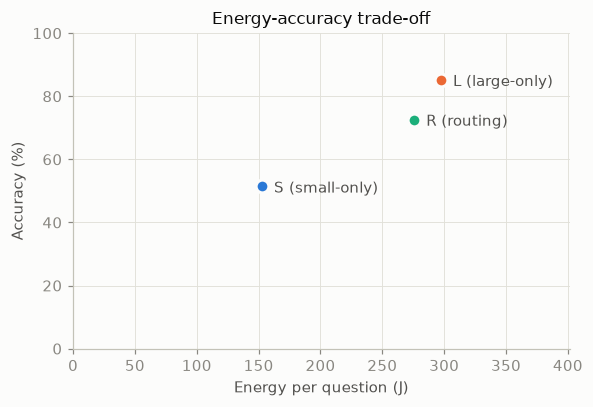

In [6]:
summary = runs.groupby("strategy", observed=True).agg(
    accuracy=("accuracy_pct", "mean"), energy=("energy_per_query_j", "mean"))
fig, ax = plt.subplots(figsize=(5.5, 3.8))

for strategy, row in summary.iterrows():
    ax.scatter(row["energy"], row["accuracy"], s=70, color=style.COLORS[strategy], zorder=3,
               edgecolor="#fcfcfb", linewidth=2)
    ax.annotate(style.label(strategy), (row["energy"], row["accuracy"]), xytext=(8, -4),
                textcoords="offset points", color=style.SECONDARY)
    
ax.set_xlabel("Energy per question (J)")
ax.set_ylabel("Accuracy (%)")
ax.set_xlim(0, summary["energy"].max() * 1.35)
ax.set_ylim(0, 100)
ax.set_title("Energy-accuracy trade-off")

plt.tight_layout()

## 4.3 Why does routing save so little energy?

This section is for interpretation. It looks at:

- **The routing decisions on the 500 experiment questions**, compared to what each model
  actually answered under S and L.
- **What R would cost if it just combined the two models' costs**, compared with what
  R actually used.

In [7]:
from sklearn.metrics import roc_auc_score

routed = data.load_queries("run_2_repetition_0").set_index("qid")
decisions = pd.DataFrame({"routed_to": routed["model"], "small_correct": answers["S"],
                          "large_correct": answers["L"]})

display(pd.crosstab(decisions["routed_to"], [decisions["small_correct"], decisions["large_correct"]],
                    rownames=["routed to"], colnames=["S correct", "L correct"]))

print(f"router AUC on the experiment questions: {roc_auc_score(answers['S'], routed['p_small_correct']):.2f}"
      " (0.5 = chance)")

per_question = runs.groupby("strategy", observed=True)["energy_per_query_j"].mean()
share_large = (routed["model"] == "large").mean()
mix = share_large * per_question["L"] + (1 - share_large) * per_question["S"]

print(f"weighted mix of S and L costs: {mix:.0f} J/question; measured R: {per_question['R']:.0f} J/question")

S correct   0        1     
L correct   0    1   0    1
routed to                  
large      49  117  11  118
small       8   69   6  122

router AUC on the experiment questions: 0.61 (0.5 = chance)
weighted mix of S and L costs: 238 J/question; measured R: 276 J/question


**Notes**

- **Accuracy.** L is right on 426 of the 500 questions (85.2%), R on 363 (72.6%), S on 257 (51.4%).
  - All three strategies differ (Cochran's Q p ≈ 10⁻⁴⁷), and so does every pair (exact
    McNemar p < 10⁻¹³).
  - R − L = −12.6 pp, 95% CI [−15.8, −9.4]. This is the **accuracy cost** of routing.
  - R is almost never right where L is wrong (6 questions); its correct answers are nearly a subset of L's.
  - The report deliberately makes no non-inferiority claim (Section 4.5).
- **Routing barely saves energy. The reason is (probably) not only the router:**
  - R sends 59% of questions to the large model, so most of the work is the same as under L.
  - Under R, both models are loaded and both GPUs are active, while the per-run baseline
    (the CPU's ~100 W) is paid for the whole run time.
  - The "weighted mix" line estimates R's cost if each question simply cost what it costs
    under S or L: 238 J. Measured R is 276 J, about 38 J per question more.
  - A likely part of that extra: under R both GPUs hold a model all the time. The 2B
    model's GPU averages 50 W under R at only 20% utilization, versus 12–14 W for an
    empty GPU (notebook 1). That's an interpretation to check, not a finding.
- **On these 500 questions, the router is better than chance, but weak.** Its AUC is 0.61;
  0.5 means it can't tell easy questions from hard ones.
  - Of the 205 questions it sends to the small model, the small model gets 128 right: 62%,
    against 51% overall.
  - 69 of those 205 are questions only L would have answered correctly, and 6 are questions only
    S answers correctly; the difference of 63 questions is exactly the 12.6 pp accuracy loss.

## 4.4 The router on the full test split

The experiment's 500 questions are a sample of the GSM8K test split. Both models' answers to all
1319 test questions are in `data/labels/test_{small,large}.jsonl`, so the saved router is also scored
on all of them, with its experiment threshold.

These labels were not produced on the testbed (see `scripts/plot_router_test_split.py`), so on the
500 experiment questions they differ slightly from the measured answers. All numbers in this
section use these labels, also the experiment-questions column, so the two columns are comparable.


In [8]:
import json
import sys
import joblib

sys.path.insert(0, str(data.EXPERIMENT_DIR.parents[2] / "llm-routing"))
import config

def test_labels(model):
    rows = sorted(map(json.loads, open(config.REPO_ROOT / "data" / "labels" / f"test_{model}.jsonl")), key=lambda r: r["qid"])
    return np.array([r["correct"] for r in rows])

questions = [json.loads(line)["question"] for line in open(config.REPO_ROOT / "data" / "dataset" / "test.jsonl")]
small_ok, large_ok = test_labels("small"), test_labels("large")
router = joblib.load(config.ROUTER_FILE)
p_small = router.predict_proba(questions)[:, list(router.classes_).index(1)]
to_small = p_small > config.ROUTER_THRESHOLD
experiment_qids = answers.index.to_numpy()

def router_summary(qids):
    boot = []
    for _ in range(5_000):
        sample = rng.choice(qids, len(qids))
        if 0 < small_ok[sample].sum() < len(sample):
            boot.append(roc_auc_score(small_ok[sample], p_small[sample]))
    share_small = to_small[qids].mean()
    return {
        "questions": len(qids),
        "AUC": roc_auc_score(small_ok[qids], p_small[qids]),
        "AUC 95% CI": np.percentile(boot, [2.5, 97.5]).round(3),
        "sent to small (%)": 100 * share_small,
        "S accuracy (%)": 100 * small_ok[qids].mean(),
        "S accuracy on questions sent to small (%)": 100 * small_ok[qids][to_small[qids]].mean(),
        "L accuracy (%)": 100 * large_ok[qids].mean(),
        "R accuracy (%)": 100 * np.where(to_small, small_ok, large_ok)[qids].mean(),
        "random routing, same share (%)": 100 * (share_small * small_ok[qids].mean()
                                                 + (1 - share_small) * large_ok[qids].mean()),
    }

pd.DataFrame({"full test split": router_summary(np.arange(len(questions))),
              "experiment questions": router_summary(experiment_qids)})


,full test split,experiment questions
questions,1319,500
AUC,0.618,0.585
AUC 95% CI,"[0.589, 0.648]","[0.534, 0.635]"
sent to small (%),42.456,41.0
S accuracy (%),52.464,52.2
S accuracy on questions sent to small (%),63.214,62.439
L accuracy (%),87.642,86.4
R accuracy (%),74.678,73.0
"random routing, same share (%)",72.707,72.378


**Notes**

- **On the full test split the router is better than chance, but weak.** AUC 0.62, with a
  95% CI that excludes 0.5. The questions it sends to the small model are easier (the small model
  solves 63% of them, against 52.5% overall).
- **It gains little over random routing:** 74.7% accuracy against 72.7% for sending the same share
  to the small model at random (also visible in `data/analysis/figures/router_test_split.png`).
- **The experiment's 500 questions behave like the full split.** With these labels the router's
  AUC on them is 0.59 (95% CI 0.53–0.64), and 0.61 with the measured answers (4.3).
  An earlier pilot sample of 100 questions had been unlucky for the router (AUC 0.45).
- This does not change the energy conclusion: a weak router still sends most questions to the large
  model, and R still pays for keeping both models loaded.